# Lasso and Ridge Regression

## A Note from sklearn on the Boston Dataset

* A message about the deprecation of the Boston dataset: [sklearn changelist](https://scikit-learn.org/stable/whats_new/v1.0.html#id9)
* The deprecation message in sklearn from v1.1: [sklearn.datasets.load_boston](https://scikit-learn.org/1.1/modules/generated/sklearn.datasets.load_boston.html)
* The Boston dataset in the sklearn v1.1 userguide: [sklearn user guide](https://scikit-learn.org/1.1/datasets/toy_dataset.html#boston-dataset)


<Axes: >

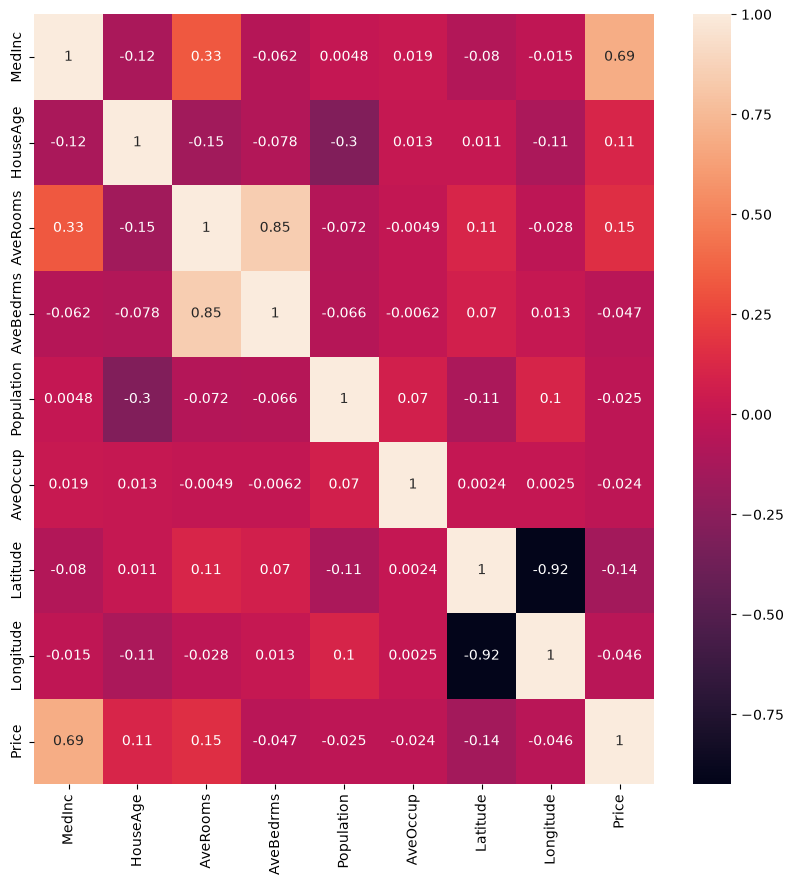

In [187]:
from sklearn.datasets import fetch_california_housing
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

housing_fetched = fetch_california_housing(data_home="../scikit_learn_data", return_X_y=True, as_frame=True, download_if_missing=False)
data, target = housing_fetched

#data = pd.DataFrame(data, columns=housing_fetched.feature_names)
data = pd.DataFrame(data)

#target variable
data['Price']=target
#preview
data.head()

#Exploration
plt.figure(figsize = (10, 10))
sns.heatmap(data.corr(), annot = True)

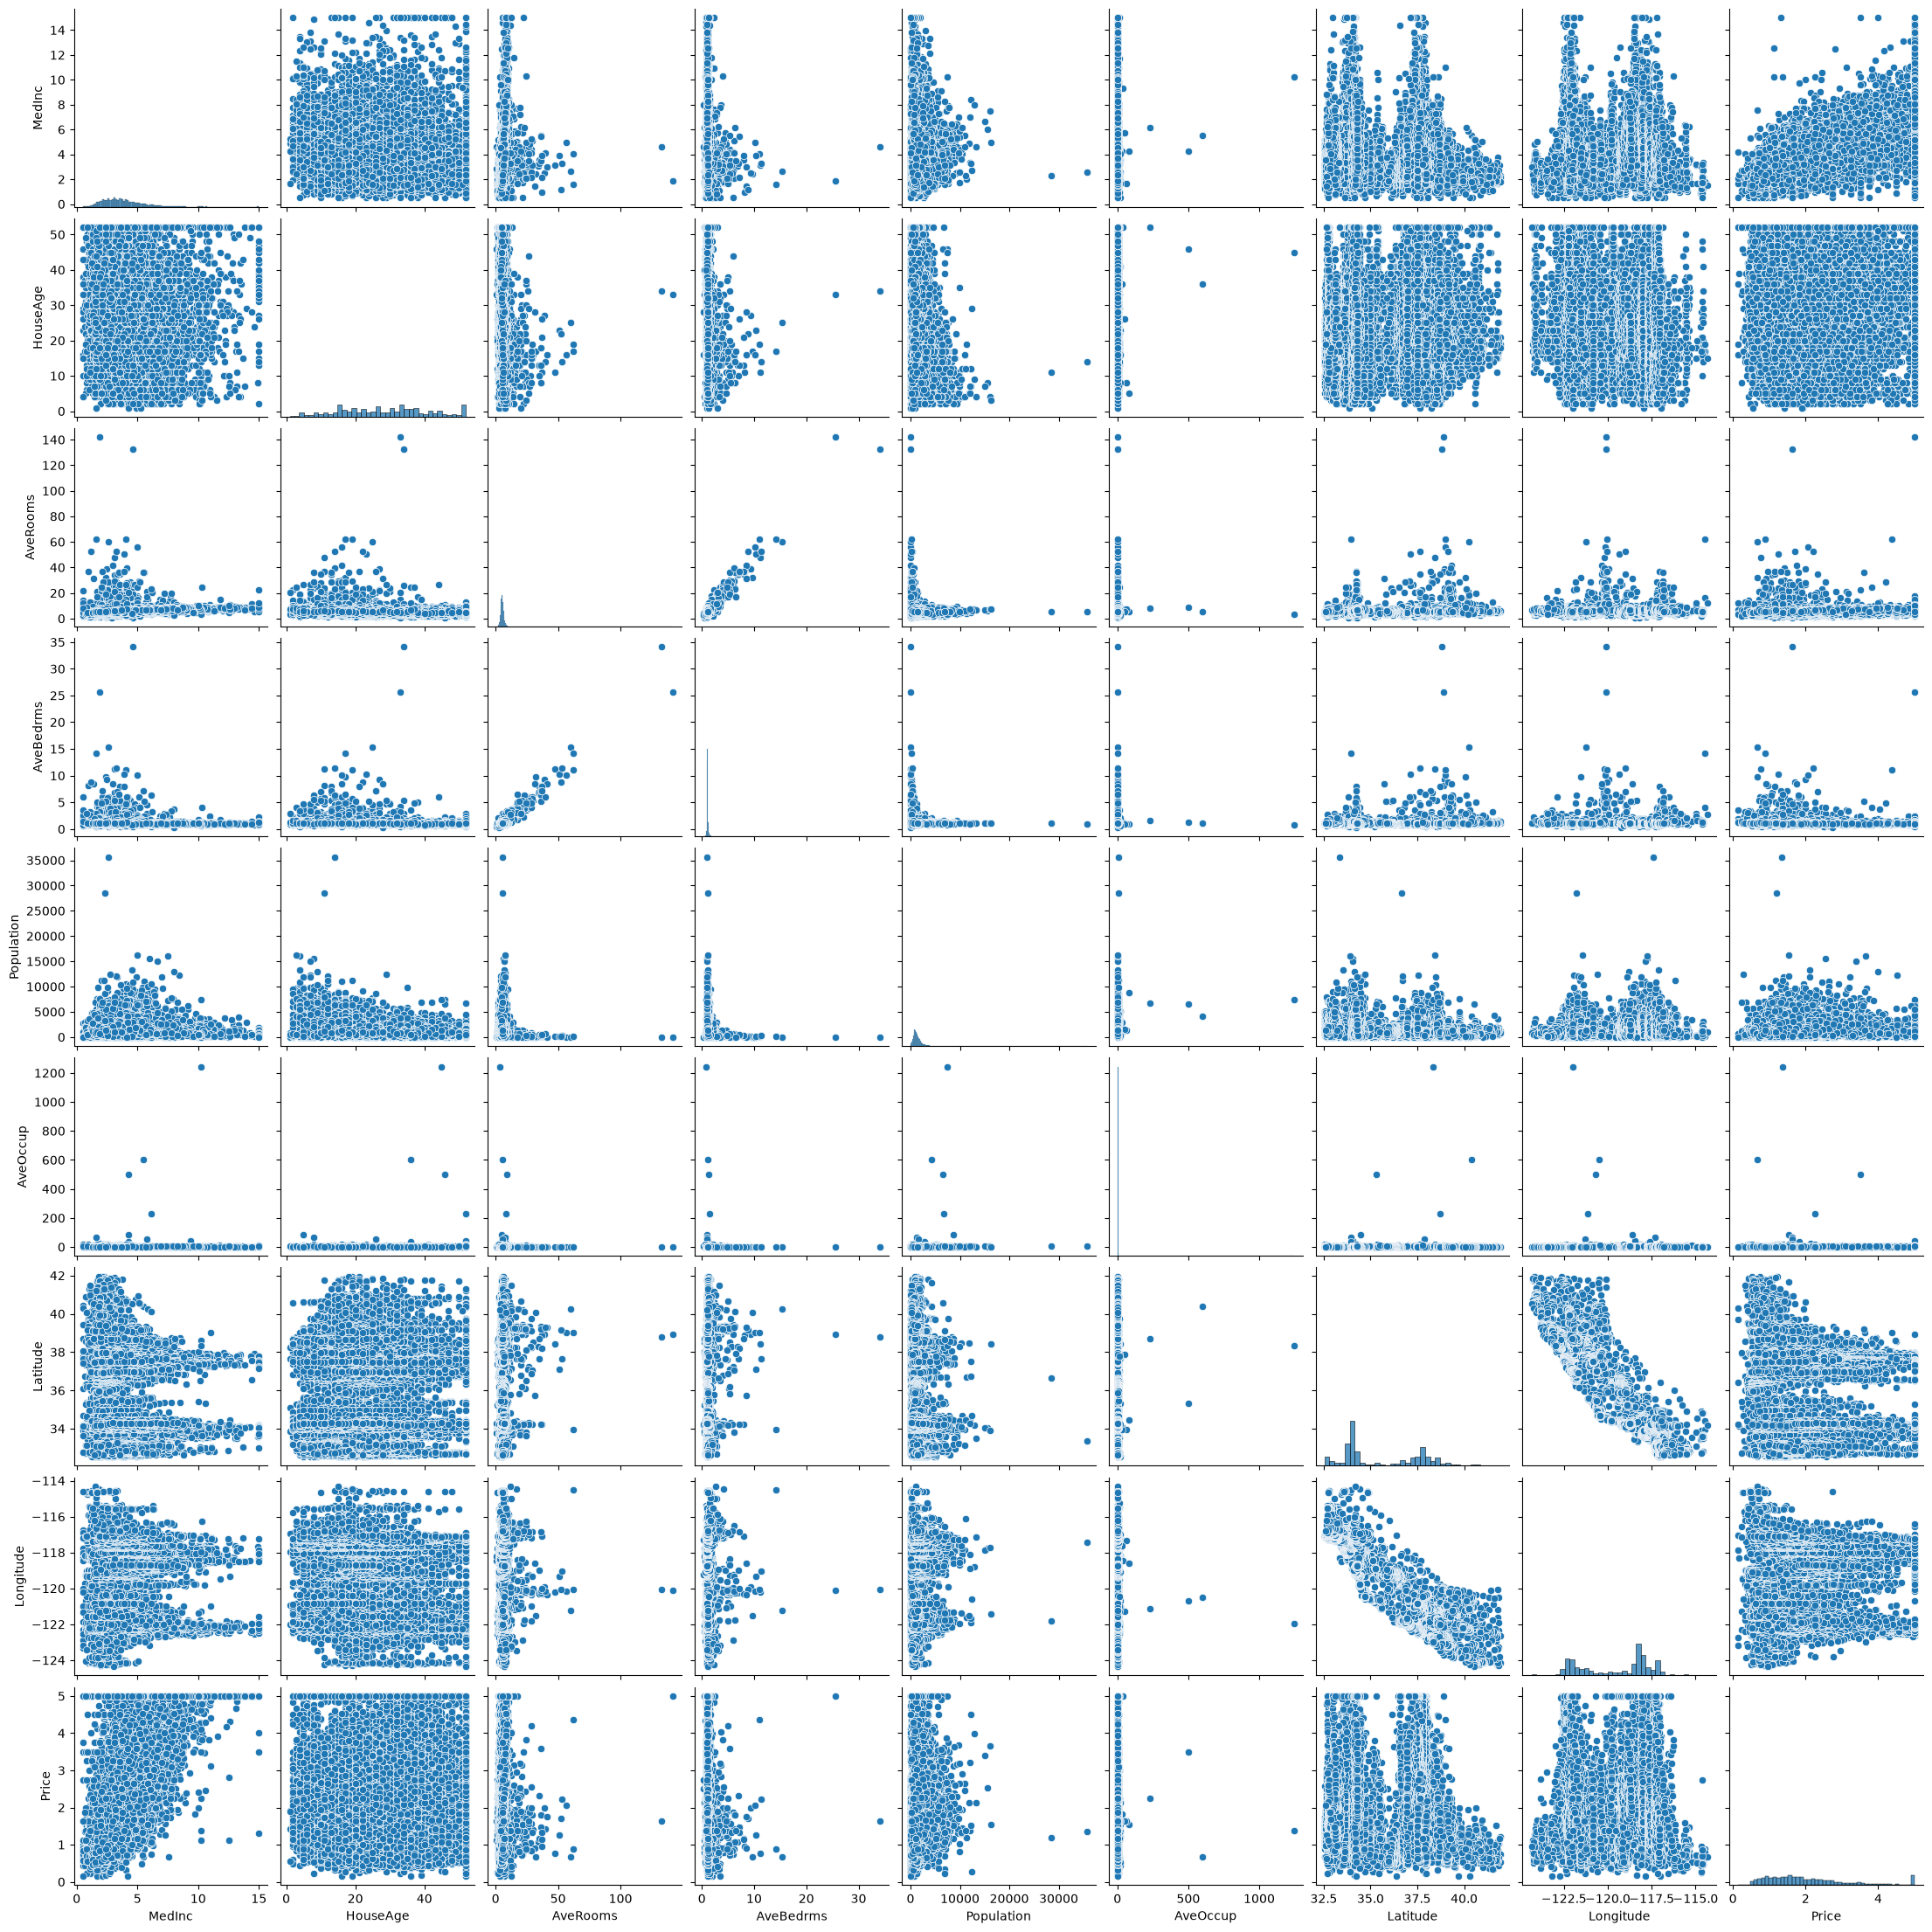

In [188]:
import numpy as np

#pairplot
data = pd.DataFrame(data)
sns.pairplot(data)

In [189]:
# AveRooms and AveBedrms are highly correlated, we will drop AveBedrms
if "AveBedrms" in data.columns:
    data = data.drop(columns = ["AveBedrms"])

The pairplot shows the outliers very clearly. Let's remove some of the outliers...

In [190]:
def look_for_outliers(df, column, remove_outliers=False):
    # Print basic statistics of the specified column
    print(df[column].describe())
    
    # Print the five highest values of the specified column
    print(f"Printing the five highest values of {column}:")
    print(df[column].nlargest(5))
    
    # Print all the rows where the specified column is greater than its 95th percentile
    print(f"Printing all rows where {column} is greater than its 95th percentile:")
    threshold = df[column].quantile(0.95)
    print(df[df[column] > threshold].sort_values(by=column, ascending=False))

    if remove_outliers:
        # Remove outliers from the specified column
        df = df[df[column] <= threshold]
    
    return df

## Trimming Values and Columns

In [243]:
trimming_outliers = True  # Set to True if you want to remove outliers
if trimming_outliers:
    # Let's trim the some columns a little more aggressively. 
    data = data[data['AveRooms'] <= 20]
    data = data[data['AveOccup'] <= 10]
    data = data[data['Population'] <= 15000]
    data = data[data['Price'] < 5.0]
    data = data[data['HouseAge'] < 52]

In [244]:
columns_to_drop = [
    "Latitude", 
    "Longitude", 
    #"HouseAge", 
    #"Population", 
    #"AveBedrms"
]

removing_columns = True  # Set to True if you want to remove specified columns
if removing_columns:
    for column in columns_to_drop:
        if column in data.columns:
            data = data.drop(columns=[column])

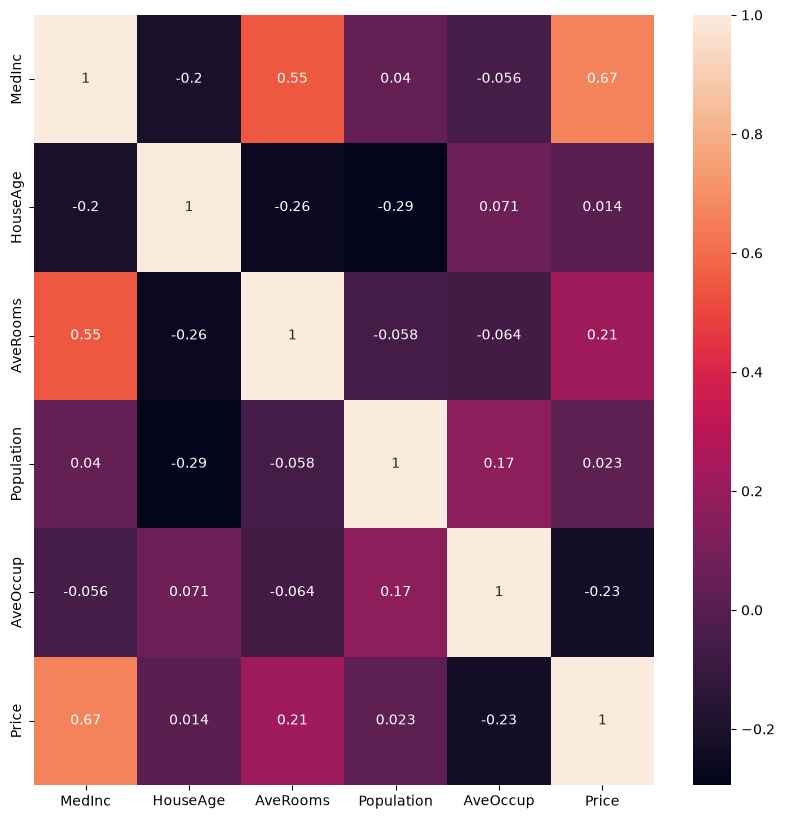

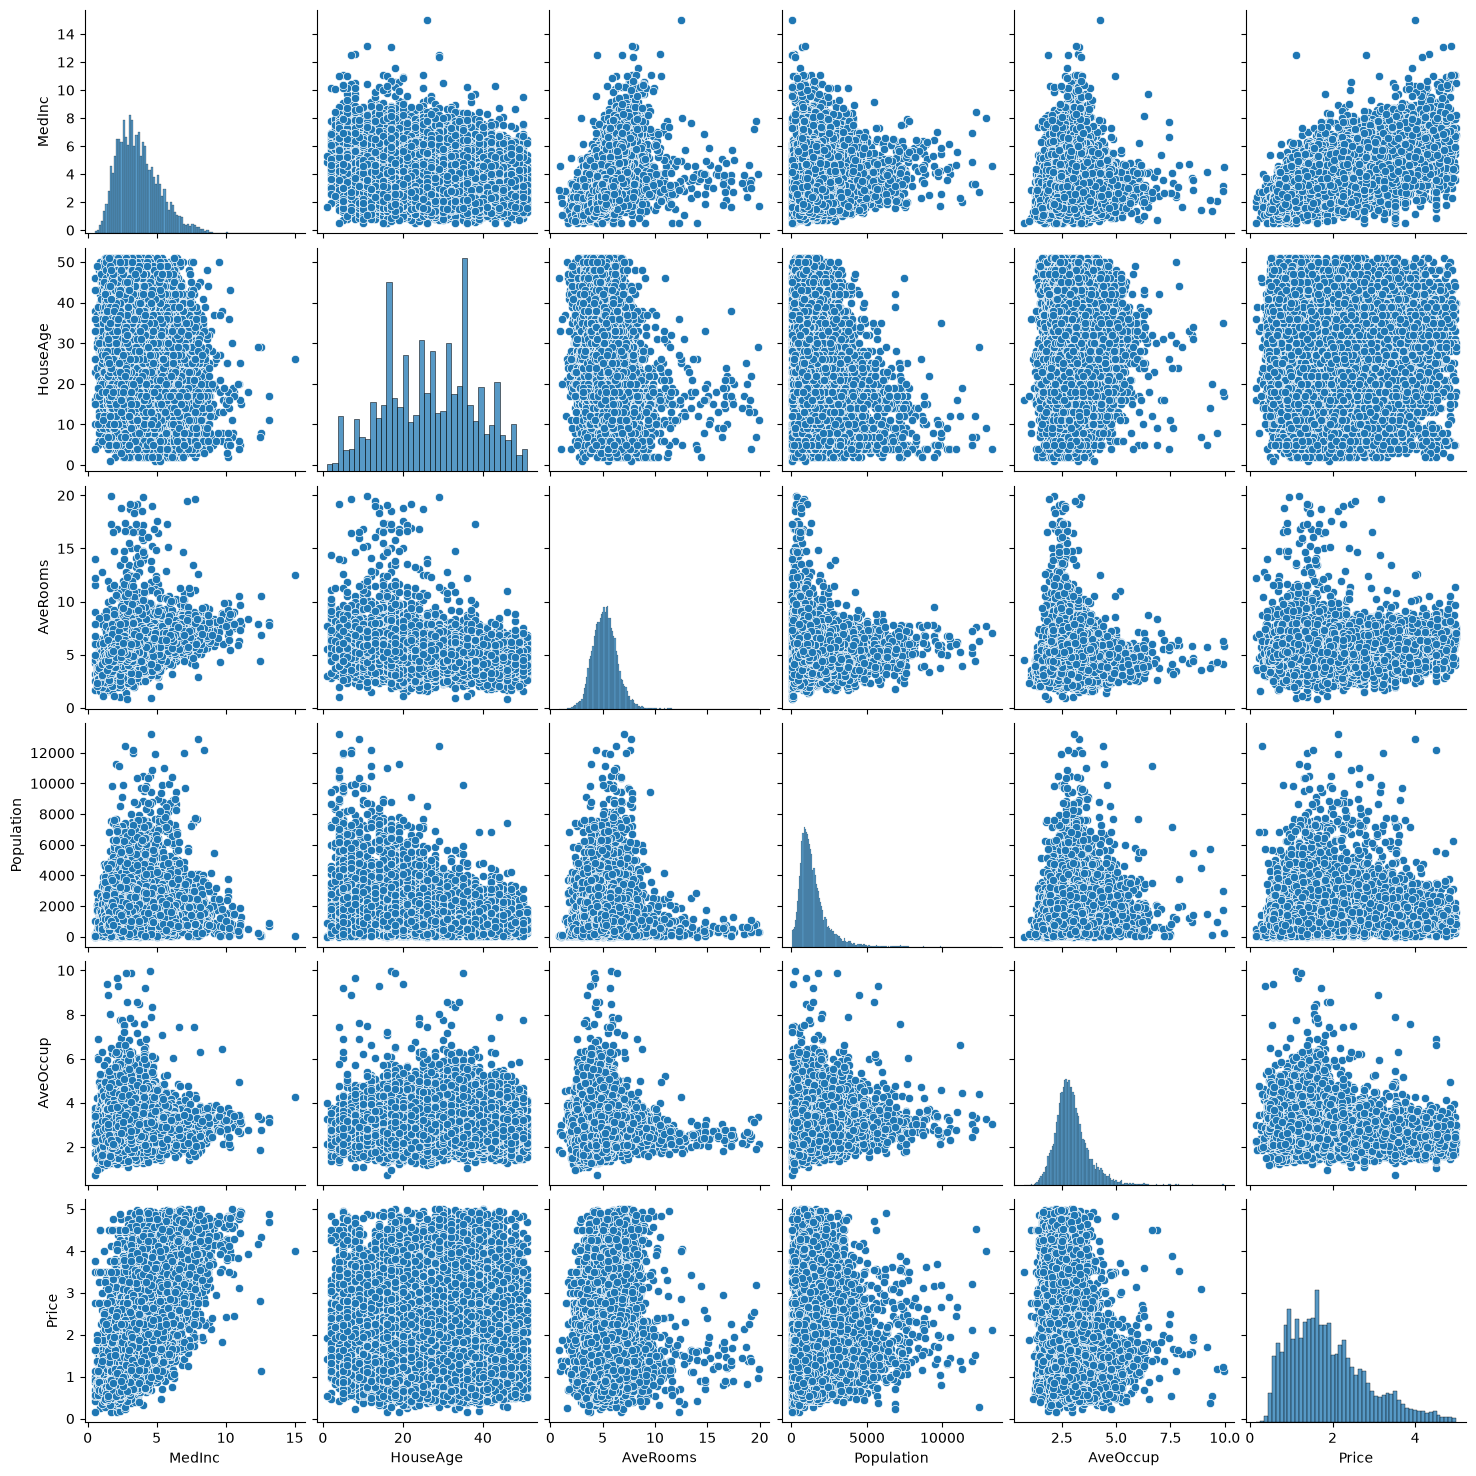

In [245]:
plt.figure(figsize = (10, 10))
sns.heatmap(data.corr(), annot = True)
sns.pairplot(data)

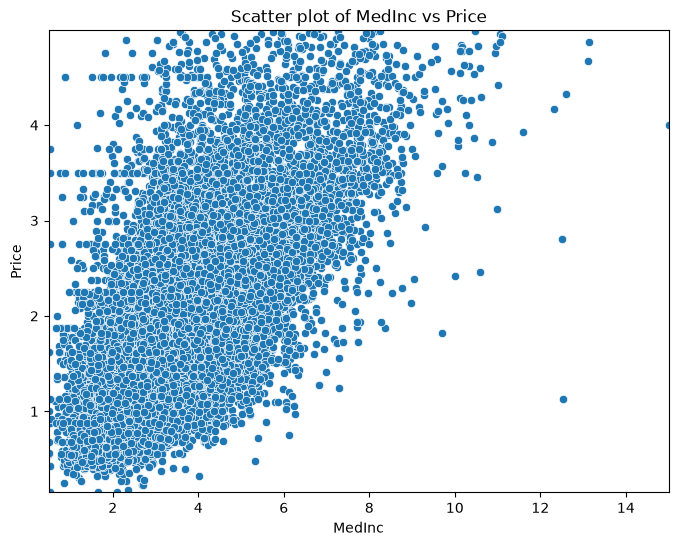

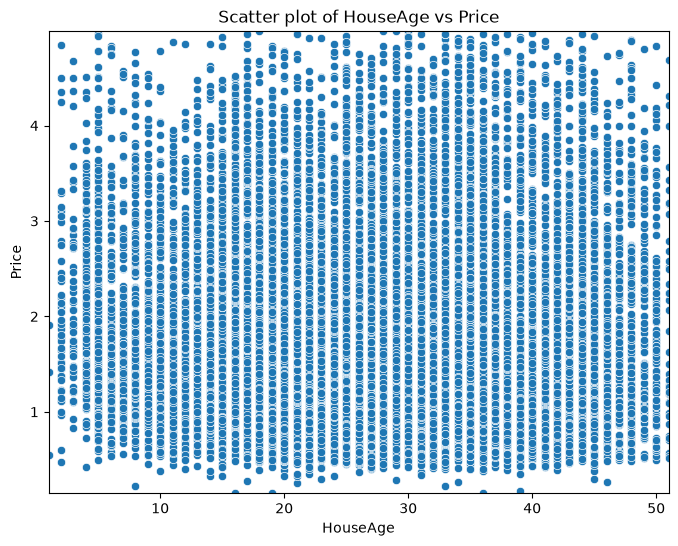

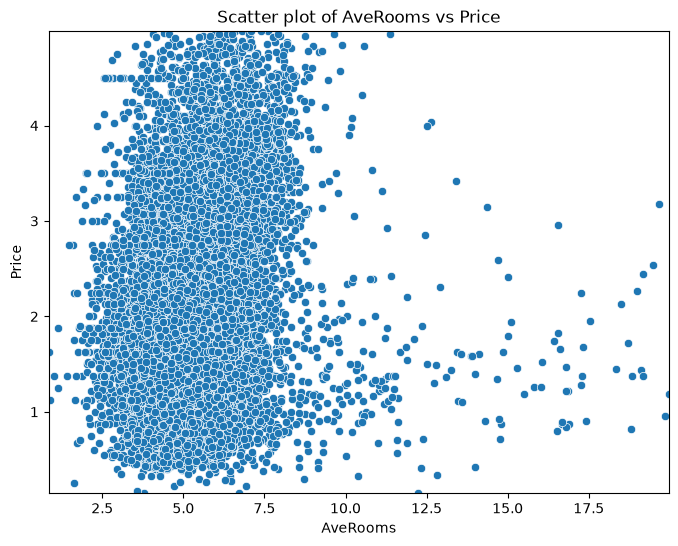

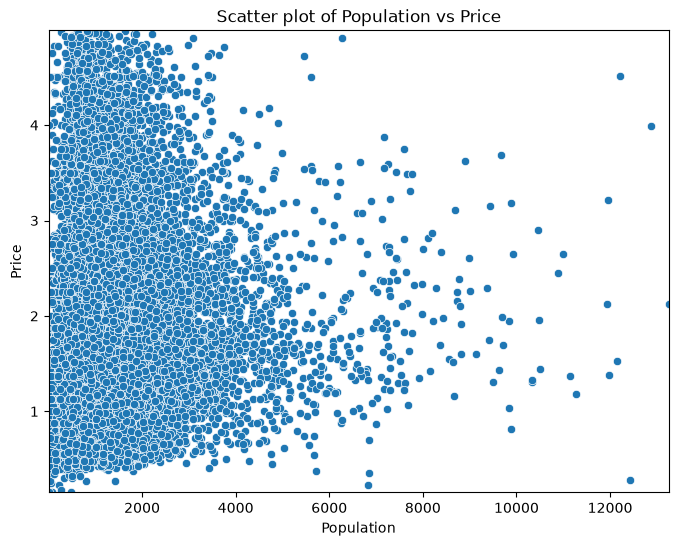

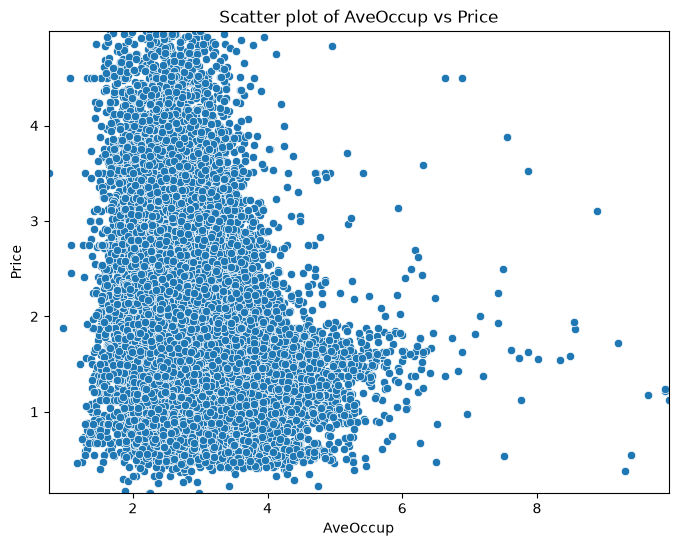

In [246]:
# Let's look at scatterplots of each of the features against the target variable to 
# see if there are any obvious relationships.

for column in data.columns:
    if column != 'Price':
        plt.figure(figsize=(8, 6))
        sns.scatterplot(x=data[column], y=data['Price'])
        plt.title(f'Scatter plot of {column} vs Price')
        plt.xlabel(column)
        plt.ylabel('Price')
        plt.xlim(data[column].min(), data[column].max())
        plt.ylim(data['Price'].min(), data['Price'].max())
        plt.show()

## Data Splitting and Scaling

In [247]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


#preview
features = data.columns[0:-1]
target = data.columns[-1]

#X and y values
X = data[features].values
y = data[target].values

#splot
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=17)

print("The dimension of X_train is {}".format(X_train.shape))
print("The dimension of X_test is {}".format(X_test.shape))

#Scale features
#scaler = StandardScaler()
#X_train = scaler.fit_transform(X_train)
#X_test = scaler.transform(X_test)


The dimension of X_train is (14763, 5)
The dimension of X_test is (3691, 5)


In [248]:
from sklearn.linear_model import LinearRegression, Ridge

#Model
lr = LinearRegression()

#Fit model
lr.fit(X_train, y_train)

#predict
#prediction = lr.predict(X_test)

#actual
actual = y_test

train_score_lr = lr.score(X_train, y_train)
test_score_lr = lr.score(X_test, y_test)

print("The train score for lr model is {}".format(train_score_lr))
print("The test score for lr model is {}".format(test_score_lr))


#Ridge Regression Model
ridgeReg = Ridge(alpha=10)

ridgeReg.fit(X_train,y_train)

#train and test scorefor ridge regression
train_score_ridge = ridgeReg.score(X_train, y_train)
test_score_ridge = ridgeReg.score(X_test, y_test)

print("\nRidge Model............................................\n")
print("The train score for ridge model is {}".format(train_score_ridge))
print("The test score for ridge model is {}".format(test_score_ridge))


The train score for lr model is 0.5420428566336268
The test score for lr model is 0.524010421680188

Ridge Model............................................

The train score for ridge model is 0.5420426941028632
The test score for ridge model is 0.524017971463128


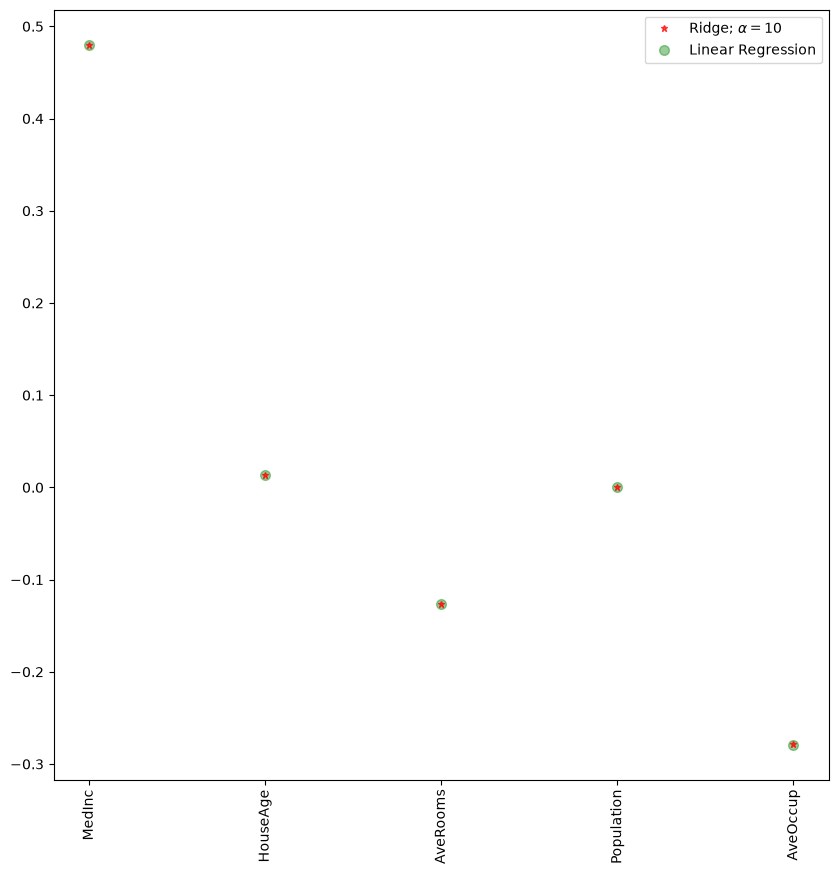

In [249]:
plt.figure(figsize = (10, 10))
plt.plot(features,ridgeReg.coef_,alpha=0.7,linestyle='none',marker='*',markersize=5,color='red',label=r'Ridge; $\alpha = 10$',zorder=7)
#plt.plot(rr100.coef_,alpha=0.5,linestyle='none',marker='d',markersize=6,color='blue',label=r'Ridge; $\alpha = 100$')
plt.plot(features,lr.coef_,alpha=0.4,linestyle='none',marker='o',markersize=7,color='green',label='Linear Regression')
plt.xticks(rotation = 90)
plt.legend()
plt.show()


In [250]:
#Lasso regression model
from sklearn.linear_model import Lasso


print("\nLasso Model............................................\n")
lasso = Lasso(alpha = 0.01)
lasso.fit(X_train,y_train)
train_score_ls =lasso.score(X_train,y_train)
test_score_ls =lasso.score(X_test,y_test)

print("The train score for ls model is {}".format(train_score_ls))
print("The test score for ls model is {}".format(test_score_ls))



Lasso Model............................................

The train score for ls model is 0.5416183056628491
The test score for ls model is 0.5236914391887051


<Axes: >

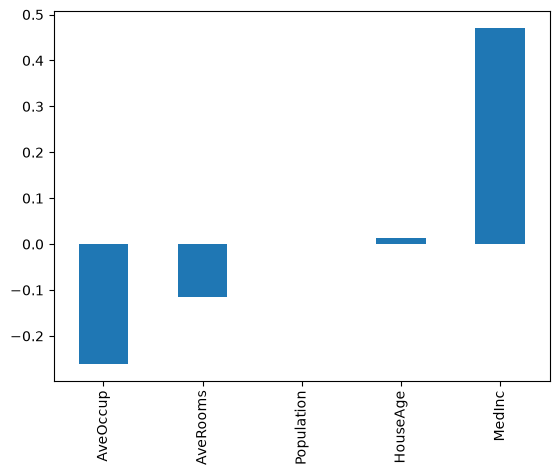

In [251]:
pd.Series(lasso.coef_, features).sort_values(ascending = True).plot(kind = "bar")

In [252]:
print(f"Number of features used in Lasso Regression: {np.sum(lasso.coef_ != 0)}")
print(f"Lasso Regression Coefficients:\n{pd.Series(lasso.coef_, features)}")

Number of features used in Lasso Regression: 5
Lasso Regression Coefficients:
MedInc        0.470909
HouseAge      0.013410
AveRooms     -0.115333
Population    0.000059
AveOccup     -0.260962
dtype: float64


In [253]:
#Using the linear CV model
from sklearn.linear_model import LassoCV

#Lasso Cross validation
lasso_cv = LassoCV(alphas = [0.0001, 0.001,0.01, 0.1, 1, 10], random_state=0).fit(X_train, y_train)


#score
print(lasso_cv.score(X_train, y_train))
print(lasso_cv.score(X_test, y_test))


0.5420428140815567
0.5240118463277543


In [254]:
#Using the Ridge CV model
from sklearn.linear_model import RidgeCV

#Ridge Cross validation
alpha_values = np.array([0.0001, 0.001, 0.01, 0.1, 1, 10])
ridge_cv = RidgeCV(alphas = alpha_values).fit(X_train, y_train)

#score
print("The train score for ridge model is {}".format(ridge_cv.score(X_train, y_train)))
print("The train score for ridge model is {}".format(ridge_cv.score(X_test, y_test)))

The train score for ridge model is 0.5420426941028764
The train score for ridge model is 0.5240179714624071


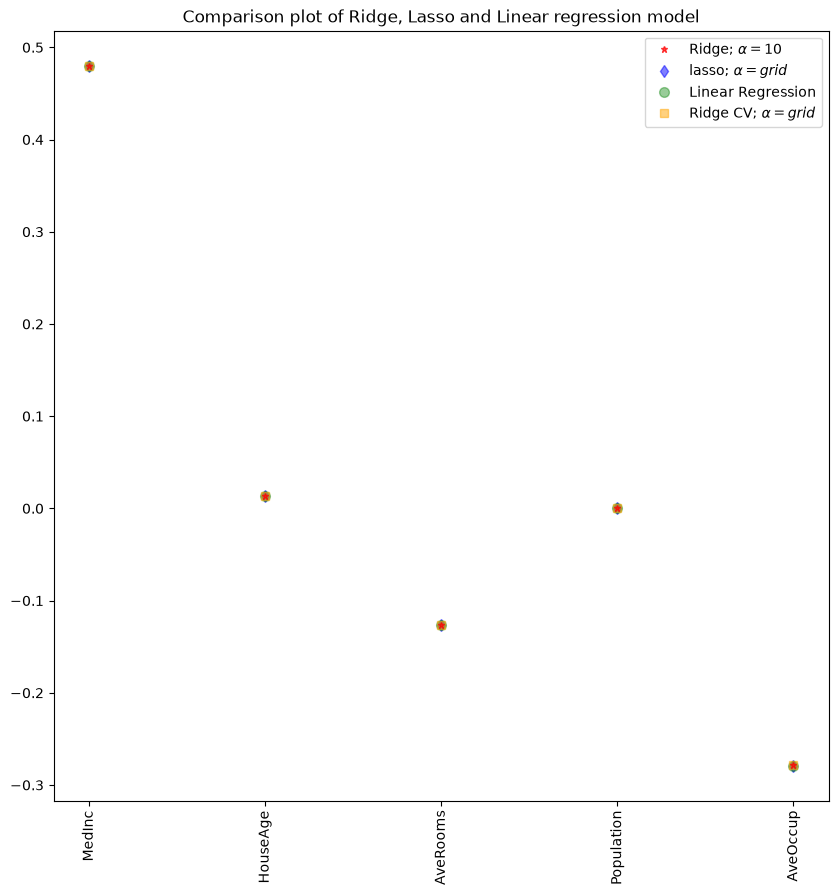

In [255]:
#plot size
plt.figure(figsize = (10, 10))
#add plot for ridge regression
plt.plot(features,ridgeReg.coef_,alpha=0.7,linestyle='none',marker='*',markersize=5,color='red',label=r'Ridge; $\alpha = 10$',zorder=7)

#add plot for lasso regression
plt.plot(lasso_cv.coef_,alpha=0.5,linestyle='none',marker='d',markersize=6,color='blue',label=r'lasso; $\alpha = grid$')

#add plot for linear model
plt.plot(features,lr.coef_,alpha=0.4,linestyle='none',marker='o',markersize=7,color='green',label='Linear Regression')

#add plot for ridge cv regression
plt.plot(ridge_cv.coef_,alpha=0.5,linestyle='none',marker='s',markersize=6,color='orange',label=r'Ridge CV; $\alpha = grid$')

#rotate axis
plt.xticks(rotation = 90)
plt.legend()
plt.title("Comparison plot of Ridge, Lasso and Linear regression model")
plt.show()
